### Swaption Pricing

In [4]:
import numpy as np
import scipy.stats as si
import tasas
from tasas import Curva
from tasas import LogLinearInterpolator
import matplotlib.pyplot as plt
from scipy.optimize import minimize

In [5]:
tenors = [1/24, 1/12, 3/12, 6/12, 9/12, 1.]
discUSD = [.999404, .998373, .9942103, .9861694, .97786314, .9697334]
curvaUSD = Curva(LogLinearInterpolator(),tenors, discUSD)
estTenors = [0.07671232876712329, 0.23013698630136986, 0.4602739726027397, 0.6904109589041096, 0.9972602739726028,
 1.9945205479452055, 2.9917808219178084, 3.989041095890411, 4.986301369863014, 9.972602739726028, 11.967123287671233,
 14.95890410958904, 19.945205479452056, 29.91780821917808]
estDisc = [0.9938720301265757, 0.9811150828234412, 0.9597032952434615, 0.9374854676578342, 0.9092344130530194,
 0.8259795908541181, 0.7497695190583412, 0.679635909082176, 0.6152873760299147, 0.3765382043313937,
 0.3065417787474897, 0.2249283946146471, 0.13445584375195552, 0.04680535077349804]
descTenors = [0.07671232876712329, 0.23013698630136986, 0.4602739726027397, 0.6904109589041096, 0.9972602739726028,
 1.9945205479452055, 2.9917808219178084, 3.989041095890411, 4.986301369863014, 9.972602739726028, 11.967123287671233,
 14.95890410958904, 19.945205479452056, 29.91780821917808]
descDisc = [0.9945006537007656, 0.9827269546377314, 0.9617026036737796, 0.9392881528609707,
 0.9078911934397116, 0.8227535289763613, 0.7415714912663142, 0.6660733687360595, 0.5957911822712506,
 0.34582165449504965, 0.27722276111342603, 0.1953687617490113, 0.10253469703860152, 0.021053373227694638]
curvaEst = Curva(LogLinearInterpolator(),estTenors, estDisc)
curvaDesc = Curva(LogLinearInterpolator(),descTenors, descDisc)


Copiamos las funciones de swaps y las extendemos ligeramente 

In [6]:
numeroDePagos = 6
tInicial = np.arange(0, numeroDePagos)
tInicial = tInicial * 28 / 365
tInicial
tStart = 9.
tInicial + tStart

array([9.        , 9.07671233, 9.15342466, 9.23013699, 9.30684932,
       9.38356164])

In [7]:
def precio_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos, nocional, strike):
    taus = [28 / 360] * numeroDePagos
    tFinal = np.arange(1, numeroDePagos + 1)
    tFinal = tFinal * 28 / 365
    tInicial = np.arange(0, numeroDePagos)
    tInicial = tInicial * 28 / 365
    tInicial = [t + tStart for t in tInicial]
    tFinal = [t + tStart for t in tFinal]
    descuentos = [curvaDesc.descuento(t) for t in tFinal]
    forwards = [curvaEst.tasa_forward(t1, t2) for (t1, t2) in zip(tInicial, tFinal)]
    swap = 0.
    for (tau, p, f) in zip(taus, descuentos, forwards):
        swap += nocional * tau *  (f - strike) * p
    return swap

def tasa_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos):
    taus = [28 / 360] * numeroDePagos
    tFinal = np.arange(1, numeroDePagos + 1)
    tFinal = tFinal * 28 / 365
    tInicial = np.arange(0, numeroDePagos)
    tInicial = tInicial * 28 / 365
    tInicial = [t + tStart for t in tInicial]
    tFinal = [t + tStart for t in tFinal]
    descuentos = [curvaDesc.descuento(t) for t in tFinal]
    forwards = [curvaEst.tasa_forward(t1, t2) for (t1, t2) in zip(tInicial, tFinal)]
    numerador = 0.
    denominador = 0.
    for (tau, p, f) in zip(taus, descuentos, forwards):
        numerador += (tau * f * p)
        denominador += (tau * p )
    return numerador / denominador

In [8]:
tasa_swap_fwd(curvaEst, curvaDesc, 2., 13)

0.09743990042986767

In [9]:
def black(F, K, sigma, T, P, CoP):
    #F: fwd rate
    #K: strike 
    #T: time to maturity
    #sigma: volatility of underlying asset
    #CoP: 1 for Call, -1 for put 
    # P: Discount factor
    
    d1 = (np.log(F / K) + (.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = (np.log(F / K) - (.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    
    option = CoP * P * (F * si.norm.cdf(CoP * d1, 0.0, 1.0) - K * si.norm.cdf(CoP * d2, 0.0, 1.0))
    return option


In [10]:
black(10., 10., .2, 1., .9, 1.)

0.7169010709865214

In [11]:
def swaption_price(curvaEst, curvaDesc, expiry, numeroDePagos, K, sigma, payerOrReceiver, N):
    #payerOrReceiver: 1 for Payer, -1 for receiver 
    # N: Notional
    F = tasa_swap_fwd(curvaEst, curvaDesc, expiry, numeroDePagos)
    taus = [28 / 360] * numeroDePagos
    tFinal = np.arange(1, numeroDePagos + 1)
    tFinal = tFinal * 28 / 365
    tFinal = [t + expiry for t in tFinal]
    descuentos = [curvaDesc.descuento(t) for t in tFinal]
    # COMPLETAR
    tau_por_desc = [tau * p for (tau, p) in zip(taus, descuentos)]
    suma_tau_p = np.sum(tau_por_desc)

    parteBlack =  black(F, K, sigma, expiry, 1., payerOrReceiver)
    swaption = suma_tau_p * parteBlack * N
    return swaption

In [12]:
swaption_price(curvaEst, curvaDesc, 1., 13, .09, .2, 1., 100000.)

977.6017129491777

In [13]:
expiry = 1.3
numeroDePagos = 26
K = .09
sigma = .2
payerOrReceiver = 1.
N = 100.
payer = swaption_price(curvaEst, curvaDesc, expiry, numeroDePagos, K, sigma, payerOrReceiver, N)
receiver = swaption_price(curvaEst, curvaDesc, expiry, numeroDePagos, K, sigma, - payerOrReceiver, N)
print("Synthetic " + str(payer - receiver))
swap = precio_swap_fwd(curvaEst, curvaDesc, expiry, numeroDePagos, N, K)
print("Swap " + str(swap))

Synthetic 1.1798149664097792
Swap 1.1798149664097792


In [14]:
def cap_price(curvaEst, curvaDesc, numeroDePagos, K, vols, capOrFloor, N): 
    # capOrFloor: 1 for cap -1 for floor
    taus = [28 / 360] * (numeroDePagos - 1)
    tFinal = np.arange(1, numeroDePagos + 1)
    tFinal = tFinal * 28 / 365
    tInicial = np.arange(0, numeroDePagos)
    tInicial = tInicial * 28 / 365
    tInicial = tInicial[1:]
    tFinal = tFinal[1:]
    descuentos = [curvaDesc.descuento(t) for t in tFinal]
    forwards = [curvaEst.tasa_forward(t1, t2) for (t1, t2) in zip(tInicial, tFinal)]
    cap = 0.
    for (tau, p, f, vol, t) in zip(taus, descuentos, forwards, vols, tInicial):
        caplet = N * tau  * black(f, K, vol, t, p, capOrFloor)
        cap = cap + caplet
    return cap

In [15]:
numeroDePagos = 39
K = .09
vols = [.20] * (numeroDePagos - 1)
capOrFloor = 1
N = 100000.
cap = cap_price(curvaEst, curvaDesc, numeroDePagos, K, vols, capOrFloor, N)
capOrFloor = -1
floor = cap_price(curvaEst, curvaDesc, numeroDePagos, K, vols, capOrFloor, N)
print("Synthetic " + str(cap - floor))
swap = precio_swap_fwd(curvaEst, curvaDesc, 28/365, numeroDePagos - 1, N, K)
print("Swap " + str(swap))

Synthetic 1778.494147663165
Swap 1778.4941476631832


## SABR

In [16]:
def _x(rho, z):
    """Return function x used in Hagan's 2002 SABR lognormal vol expansion."""
    a = (1 - 2*rho*z + z**2)**.5 + z - rho
    b = 1 - rho
    return np.log(a / b)
def sabr_vol(k, f, t, alpha, beta, rho, volvol):
    """
    Hagan's 2002 SABR lognormal vol expansion.
    The strike k can be a scalar or an array, the function will return an array
    of lognormal vols.
    """
    # Negative strikes or forwards
    if k <= 0 or f <= 0:
        return 0.
    eps = 1e-07
    logfk = np.log(f / k)
    fkbeta = (f*k)**(1 - beta)
    a = (1 - beta)**2 * alpha**2 / (24 * fkbeta)
    b = 0.25 * rho * beta * volvol * alpha / fkbeta**0.5
    c = (2 - 3*rho**2) * volvol**2 / 24
    d = fkbeta**0.5
    v = (1 - beta)**2 * logfk**2 / 24
    w = (1 - beta)**4 * logfk**4 / 1920
    z = volvol * fkbeta**0.5 * logfk / alpha
    # if |z| > eps
    if abs(z) > eps:
        vz = alpha * z * (1 + (a + b + c) * t) / (d * (1 + v + w) * _x(rho, z))
        return vz
    # if |z| <= eps
    else:
        v0 = alpha * (1 + (a + b + c) * t) / (d * (1 + v + w))
        return v0


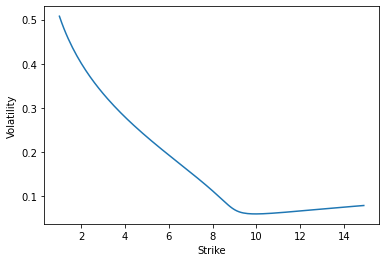

In [17]:
import numpy as np
#Normalmente queremos encontrar los parámetros que devuelvan las volatilidades de mercado
alpha = .2
beta = 1.
rho = -0.99
volvol = .5

f = 6.0
t = 1.
Ks = np.arange(1., 15., .1)
vols = [sabr_vol(k, f, t, alpha, beta, rho, volvol) for k in Ks]
import matplotlib.pyplot as plt
plt.plot(Ks, vols);
plt.xlabel("Strike");
plt.ylabel("Volatility");

### Ejercicio
Calibra el smile a un swaption 6N x 65N
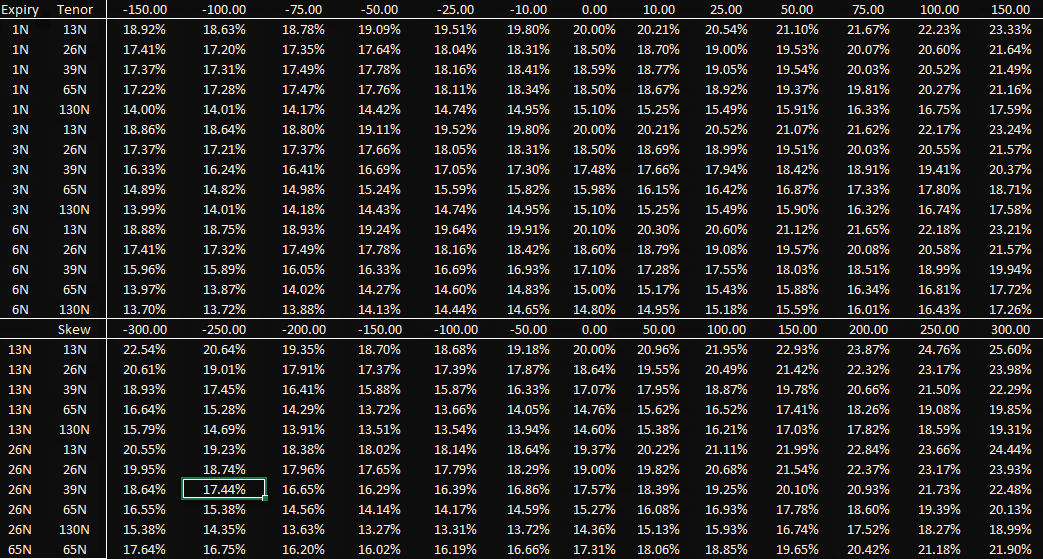

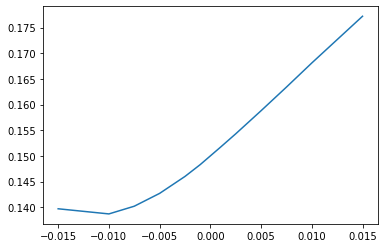

In [18]:
relativeStrikes = [-150., -100., -75., -50., -25. , -10., 0., 10., 25.,50., 75., 100., 150.]
relativeStrikes = [k / 10000. for k in relativeStrikes]
mktVols = [13.97, 13.87, 14.02, 14.27, 14.60, 14.83, 15.00, 15.17, 15.43, 15.88, 16.34, 16.81, 17.72]
mktVols = [v / 100.  for v in mktVols]

plt.plot(relativeStrikes, mktVols)

In [19]:
curvaDesc

In [20]:
tStart = 28 * 6 / 365.
numeroDePagos = 65
f = tasa_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos)


In [21]:
def sabr_vols(sabrParams, f, t, relativeStrikes, beta):
    """
    Returns the vol for every strike based on SABR
    """
    alpha = sabrParams[0]
    rho = sabrParams[1]
    volvol = sabrParams[2]
    # Strikes 
    Ks = [f + k for k in  relativeStrikes]
    #COMPLETAR
    sabrVols = [sabr_vol(k, f, t, alpha, beta, rho, volvol) for k in Ks]
    return sabrVols

In [22]:
def funcion_sabr_optimizar_3_parametros(sabrParams, f, mktVols, relativeStrikes, tStart, curvaEst, curvaDesc, beta):
    """
    Raiz de la suma de los cuadrados de la diferencia ente la vol sabr y la vol de mercado
    sabrParams es un vector , en la primera entrada tiene alpha, en la segunda rho y en la tercera volvol
    """
    #COMPLETAR 
    pesos = [(1-(i)**2)**1000 for i in relativeStrikes] #ponderando mayormente el ATM
    #pesos = len(relativeStrikes)*[1]#Pesos iguales
    sabrVols = sabr_vols(sabrParams, f, tStart, relativeStrikes, beta)
    diff = [w*(volSABR - volMkt) ** 2 for (w,volSABR, volMkt)  in zip(pesos,sabrVols, mktVols )] 
    return np.sqrt(np.sum(diff))

In [23]:
def calibrar_vol_smile_1(mktVols, relativeStrikes, tStart, numeroDePagos, curvaEst, curvaDesc,beta=1.):
    
    #COMPLETAR - CAlcular fwd y funcion a optimizar
    f = tasa_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos)
    fOpt = lambda x: funcion_sabr_optimizar_3_parametros(x, f, mktVols, relativeStrikes, 
                                                         tStart, curvaEst, curvaDesc, beta)
    alpha0 = mktVols[relativeStrikes.index(0.)]
    rho0 = 0.
    volvol0 = .2
    # alpha>0, rho entre -1 y 1,  nu >0
    bnds = ((.000001, None), (-.9999, .99999), (0.00000001, None))
    res = minimize(fOpt, (alpha0, rho0, volvol0), bounds=bnds)
    return res.x

In [24]:
beta = 1.
sabr_params = calibrar_vol_smile_1(mktVols, relativeStrikes, tStart, numeroDePagos, curvaEst, curvaDesc,beta=1.)
sabr_params

array([0.14703493, 0.43527473, 0.71208898])

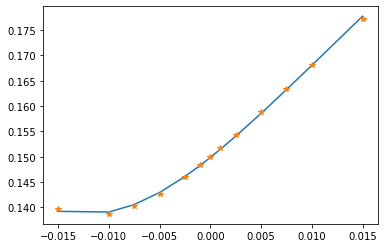

In [25]:
sabrVols = sabr_vols(sabr_params, f, tStart, relativeStrikes, beta)
plt.plot(relativeStrikes, sabrVols);
plt.plot(relativeStrikes, mktVols, '*');

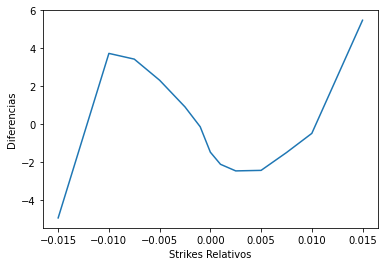

In [26]:
plt.plot(relativeStrikes, [(i-j)*10000 for (i,j) in zip(sabrVols,mktVols)]);
plt.xlabel('Strikes Relativos');
plt.ylabel('Diferencias');

In [27]:
sabrVols[relativeStrikes.index(0.)] - mktVols[relativeStrikes.index(0.)]

-0.00014699858502933982

### Ejercicio:
0 ) Evalua un swaption 6N x 65N con strike de 12.1 receiver y nocional de 100,000

a) Evalua un swap con expiracion 5N y tenor 65N

b) Evalua un swap con expiracion 6N y tenor 91N

c) Evalua un swap con expiracion 5N y tenor 91N

In [28]:
tStart = 28 * 6 / 365.
numeroDePagos = 65
f = tasa_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos)

K = .121
sigma = sabr_vol(K, f, tStart, sabr_params[0], 1., sabr_params[1], sabr_params[2])
print(sigma)
swaption_price(curvaEst, curvaDesc, tStart, numeroDePagos, K, sigma, -1., 100000.)

0.19194574283718804


8611.701196927383

a) 

In [29]:
sabr_params6x65 = sabr_params

In [30]:
# Calibrar SABR a 3Nx65N
mktVols3x65 = [14.89, 14.82, 14.98, 15.24, 15.59, 15.82, 15.98, 16.15, 16.42, 16.87, 17.33, 17.80, 18.71]
mktVols3x65 = [v / 100.  for v in mktVols3x65]
tStart = 28 * 5 / 365.
numeroDePagos = 65
f = tasa_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos)
sabr_params3x65 = calibrar_vol_smile_1(mktVols3x65, relativeStrikes, tStart, numeroDePagos, curvaEst, curvaDesc,beta=1.)
sabr_params3x65

array([0.15706179, 0.4311296 , 0.72406858])

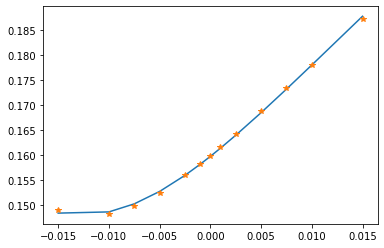

In [31]:
sabrVols = sabr_vols(sabr_params3x65, f, tStart, relativeStrikes, beta)
plt.plot(relativeStrikes, sabrVols)
plt.plot(relativeStrikes, mktVols3x65, '*')

In [32]:
from scipy.interpolate import interp1d
# interpolar en parametros (alpha3N y alpha6N para encontrar alpha5N interpolacion )
alpha3x65 = sabr_params3x65[0]
rho3x65 = sabr_params3x65[1]
nu3x65 = sabr_params3x65[2]

alpha6x65 = sabr_params6x65[0]
rho6x65 = sabr_params6x65[1]
nu6x65 = sabr_params6x65[2]

ts = [28. * 3. / 365., 28. * 6./ 365.]
alphas = [alpha3x65, alpha6x65]
alphaFunctor = interp1d(ts, alphas)
alpha = alphaFunctor(28. * 4. / 365)

# interpolar en parametros (rho3N y rho6N para encontrar rho5N interpolacion )
rhos = [rho3x65, rho6x65]
rhoFunctor = interp1d(ts, rhos)
rho = rhoFunctor(28. * 4. / 365)
# interpolar en parametros (nu3N y nu6N para encontrar nu5N interpolacion )
nus = [nu3x65, nu6x65]
nuFunctor = interp1d(ts, nus)
nu = nuFunctor(28. * 4. / 365)

print(alpha)
print (rho)
print(nu)

0.1537195010766399
0.4325113081071386
0.7200753766673205


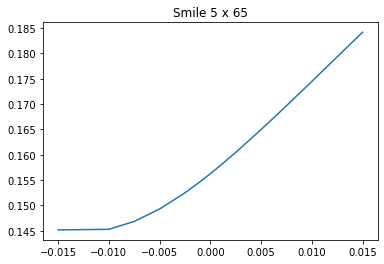

In [33]:
sabr_params5x65 = [alpha,rho,nu]
sabrVols = sabr_vols(sabr_params5x65, f, tStart, relativeStrikes, beta)
plt.plot(relativeStrikes, sabrVols)
plt.title('Smile 5 x 65');

b) Evalua un swap con expiracion 6N y tenor 91N


In [34]:
#Calibrar sabr a 6Nx130N
mktVols6x130 = [13.70, 13.72, 13.88, 14.13, 14.44, 14.65, 14.80, 14.95, 15.18, 15.59, 16.01, 16.43, 17.26]
mktVols6x130 = [v / 100.  for v in mktVols6x130]
tStart = 28 * 6 / 365.
numeroDePagos = 130
f = tasa_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos)
sabr_params6x130 = calibrar_vol_smile_1(mktVols6x130, relativeStrikes, tStart, numeroDePagos, curvaEst, curvaDesc,beta=1.)
sabr_params6x130

array([0.14554668, 0.44017648, 0.64571841])

Interpolar para encontrar el valor de un Swaption 5 x 91

In [35]:
from scipy.interpolate import interp1d
# interpolar en parametros (alpha3N y alpha6N para encontrar alpha5N interpolacion )
alpha6x130 = sabr_params6x130[0]
rho6x130 = sabr_params6x130[1]
nu6x130 = sabr_params6x130[2]

alpha6x65 = sabr_params6x65[0]
rho6x65 = sabr_params6x65[1]
nu6x65 = sabr_params6x65[2]
ts = [28 * 65 /365, 28 * 130 /365]
alphas = [alpha6x65, alpha6x130]
alphaFunctor = interp1d(ts, alphas)
alpha = alphaFunctor(28 * 91/365)

# interpolar en parametros (rho3N y rho6N para encontrar rho5N interpolacion )
rhos = [rho6x65, rho6x130]
rhoFunctor = interp1d(ts, rhos)
rho = rhoFunctor(28 * 91/365)
# interpolar en parametros (nu3N y nu6N para encontrar nu5N interpolacion )
nus = [nu6x65, nu6x130]
nuFunctor = interp1d(ts, nus)
nu = nuFunctor(28 * 91/365)

print(alpha)
print (rho)
print(nu)

0.14643962819259276
0.43723543154167976
0.6855407508830546


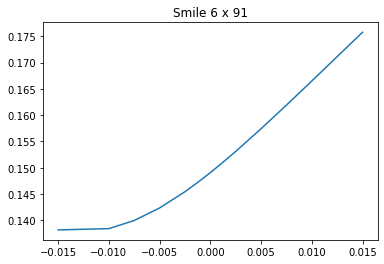

In [36]:
sabr_params5x65 = [alpha,rho,nu]
sabrVols = sabr_vols(sabr_params5x65, f, tStart, relativeStrikes, beta)
plt.plot(relativeStrikes, sabrVols)
plt.title('Smile 6 x 91');

In [37]:
# b) Evalua un swap con expiracion 6N y tenor 91N
tStart = 28 * 6 / 365.
numeroDePagos = 91
f = tasa_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos)

K = .121
sigma = sabr_vol(K, f, tStart, alpha, 1., rho, nu)
print(sigma)
swaption_price(curvaEst, curvaDesc, tStart, numeroDePagos, K, sigma, -1., 100000.)

0.18933958804454146


10909.629148298385

# CAPS y FLOORS


In [38]:
class CapSurface: 
    # ts: lista con tiempos asociados a los factores de descuento
    # ps: lista con factores de descuento
    def __init__(self, ts, alphas, rhos, nus, beta, curvaEst, curvaDesc):
        self._ts = ts
        self._alphas = alphas
        self._rhos = rhos
        self._nus = nus
        self._beta = beta
        self._curvaEst = curvaEst
        self._curvaDesc = curvaDesc
        
    def get_ts(self):
        return self._ts
    def get_curvaDesc(self):
        return self._curvaDesc
    def get_curvaEst(self):
        return self._curvaEst
    
    def get_alphas(self):
        return self._alphas
    
    def get_rhos(self):
        return self._rhos
    
    def get_nus(self):
        return self._nus
    
    def vol_caplet(self, t1, t2, k):
        if (t >= self._ts[-1]):
            alpha =  self._alphas[-1] 
            rho =  self._rhos[-1] 
            nu =  self._nus[-1] 
        elif (t <= self._ts[0]):
            alpha =  self._alphas[0] 
            rho =  self._rhos[0] 
            nu =  self._nus[0] 
        else:
            alphaFunctor = interp1d(self._ts, self._alphas)
            rhoFunctor = interp1d(self._ts, self._rhos)
            nuFunctor = interp1d(self._ts, self._nus)
            alpha =  alphaFunctor(t)
            rho =  rhoFunctor(t)
            nu =  nuFunctor(t)
        f = self._curvaEst.tasa_forward(t1, t2)
        vol = sabr_vol(k, f, t1, alpha, self._beta, rho, nu)
        return vol
    
    def cap_price(self,numeroDePagos, K, capOrFloor, N): 
        curvaEst = self._curvaEst 
        curvaDesc = self._curvaDesc 
        # capOrFloor: 1 for cap -1 for floor
        taus = [28 / 360] * (numeroDePagos - 1)
        tFinal = np.arange(1, numeroDePagos + 1)
        tFinal = tFinal * 28 / 365
        tInicial = np.arange(0, numeroDePagos)
        tInicial = tInicial * 28 / 365
        tInicial = tInicial[1:]
        tFinal = tFinal[1:]
        descuentos = [curvaDesc.descuento(t) for t in tFinal]
        forwards = [curvaEst.tasa_forward(t1, t2) for (t1, t2) in zip(tInicial, tFinal)]
        cap = 0.
        for (tau, p, f,  t) in zip(taus, descuentos, forwards,  tInicial):
            vol = self.vol_caplet(t, t + (28/360), K)
            caplet = N * tau  * black(f, K, vol, t, p, capOrFloor)
            cap = cap + caplet
        return cap
    
    def agregar_nodo(self, t, alpha, rho, nu):
        self._ts.append(t)
        self._alphas.append(alpha)
        self._rhos.append(rho)
        self._nus.append(nu)
        
    def cambiar_ultimo_nodo(self, alpha, rho, nu):
        self._alphas[-1] = alpha
        self._rhos[-1] = rho
        self._nus[-1] = nu
    

In [39]:
from scipy import optimize 
def parvol2price(parVol, curvaEst, curvaDesc, numeroDePagos, K, capOrFloor, N):
    vols = [parVol] * (numeroDePagos - 1)
    return cap_price(curvaEst, curvaDesc, numeroDePagos, K, vols, capOrFloor, N)

def par_vol(precio, curvaEst, curvaDesc, numeroDePagos, K, capOrFloor, N):
    # Par vol implicita
    fOpt = lambda x: parvol2price(x, curvaEst, curvaDesc, numeroDePagos, K, capOrFloor, N) - precio
    a=.19
    b = .20
    while (fOpt(a) * fOpt(b) > 0 and a >0.):
        a = a -.001
        b = b +.001
    parVol = optimize.brentq(fOpt, a, b)
    return parVol


def par_vol_newton(precio, curvaEst, curvaDesc, numeroDePagos, K, capOrFloor, N):
    # Par vol implicita
    fOpt = lambda x: parvol2price(x, curvaEst, curvaDesc, numeroDePagos, K, capOrFloor, N) - precio
    x0=.19
    parVol = optimize.newton(fOpt, x0)
    return parVol
    

In [57]:
numeroDePagos = 39
K = .09
vols = [.30] * (numeroDePagos - 1)
capOrFloor = 1
N = 100000.
cap = cap_price(curvaEst, curvaDesc, numeroDePagos, K, vols, capOrFloor, N)
capOrFloor = -1
floor = cap_price(curvaEst, curvaDesc, numeroDePagos, K, vols, capOrFloor, N)


print(par_vol(floor, curvaEst, curvaDesc, numeroDePagos, K, capOrFloor, N))

0.3000000000000001


In [41]:
beta = 1.
alpha = .14408057
rhos = 0.4345083
nu =  .6978216
ts = [1.]
alphas = [alpha]
rhos = [rho]
nus = [nu]
capSurface = CapSurface(ts, alphas, rhos, nus, beta, curvaEst, curvaDesc)

In [42]:
smileCaps = [23.63, 20.10, 17.18, 14.68, 12.72, 13.03, 14.79, 16.74, 18.71, 20.58, 22.31, 23.90, 25.37]
strikesRelativos = [-300, -250, -200, -150, -100, -50 , 0 , 50, 100, 150, 200, 250, 300]
numeroDePagos = 13
smileCaps = [s /100. for s in smileCaps]
strikesRelativos = [s /10000. for s in strikesRelativos]

In [58]:
from scipy.optimize import fmin
numeroDePagos = 13
capSurface = CapSurface(ts, alphas, rhos, nus, beta, curvaEst, curvaDesc)
sabrParams = [.14408057, 0.4345083 , 0.6978216 ]
N = 1000000000.
alpha = sabrParams[0]
rho = sabrParams[1]
nu = sabrParams[2]
curvaEst = capSurface.get_curvaEst()
curvaDesc = capSurface.get_curvaDesc()
F = tasa_swap_fwd(curvaEst, curvaDesc, 0., numeroDePagos)
capOrFloors = [1. if stkRel >= 0. else -1. for stkRel in strikesRelativos]
F

0.09560000000000395

In [59]:
pricesSurface = [capSurface.cap_price(numeroDePagos, F + stkRel, capOrFloor, N) 
                 for (stkRel, capOrFloor) in zip(strikesRelativos, capOrFloors)] 
pricesMkt = [parvol2price(parVol, curvaEst, curvaDesc, numeroDePagos, F + stkRel, capOrFloor, N) for
             (stkRel, parVol, capOrFloor) in zip(strikesRelativos, smileCaps, capOrFloors)]

print(pricesSurface)
print(pricesMkt)

[3017.703889905719, 8291.045380422698, 25888.194434737503, 122312.0278447684, 584416.989808507, 1689500.0060115817, 4724229.405315498, 2951958.9433797495, 1842333.2333106534, 1175607.0102025182, 775041.5633016777, 529104.2808509031, 373429.36289318744]
[51152.09628754168, 54362.91135826029, 73443.19637141482, 149857.1454871816, 488759.7915160019, 1574131.2586437967, 4832620.440025334, 3339914.7138935477, 2425098.201424869, 1841586.5817953302, 1447610.6466546664, 1168167.3584601213, 962968.751785239]


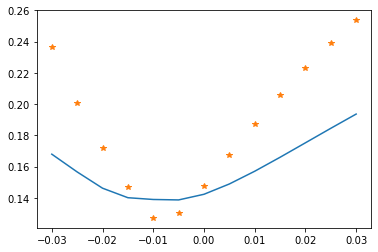

In [60]:
parVolSurface = [par_vol(precio, curvaEst, curvaDesc, numeroDePagos, F + stkRel, capOrFloor, N) 
                 for (precio, stkRel, capOrFloor) in zip(pricesSurface, strikesRelativos, capOrFloors)]
plt.plot(strikesRelativos, parVolSurface)
plt.plot(strikesRelativos, smileCaps, '*')


In [61]:
def fParVolsToOptimize(sabrParams, capSurface, strikesRelativos, smileCaps, numeroDePagos):
    N = 1_000_000_000.
    alpha = sabrParams[0]
    rho = sabrParams[1]
    nu = sabrParams[2]
    capSurface.cambiar_ultimo_nodo(alpha, rho, nu)
    curvaEst = capSurface.get_curvaEst()
    curvaDesc = capSurface.get_curvaDesc()
    F = tasa_swap_fwd(curvaEst, curvaDesc, 0., numeroDePagos)
    capOrFloors = [1. if stkRel >= 0. else -1. for stkRel in strikesRelativos]
    pricesSurface = [capSurface.cap_price(numeroDePagos, F + stkRel, capOrFloor, N) 
                     for (stkRel, capOrFloor) in zip(strikesRelativos, capOrFloors)] 
#     parVolSurface = [par_vol(precio, curvaEst, curvaDesc, numeroDePagos, F + stkRel, capOrFloor, N) 
#                      for (precio, stkRel, capOrFloor) in zip(pricesSurface, strikesRelativos, capOrFloors)] 
    pricesMkt = [parvol2price(parVol, curvaEst, curvaDesc, numeroDePagos, F + stkRel, capOrFloor, N) for
                 (stkRel, parVol, capOrFloor) in zip(strikesRelativos, smileCaps, capOrFloors)]
    
    return np.sqrt(np.sum([N * (priceSurface - priceMkt) ** 2 for (priceSurface,priceMkt) in zip(pricesSurface, pricesMkt)]))

    

In [62]:
sabrParams

[0.14408057, 0.4345083, 0.6978216]

In [63]:

fOpt3 = lambda x: fParVolsToOptimize(x, capSurface, strikesRelativos, smileCaps, numeroDePagos)
bnds = ((.000001, None), (-.9999, .99999), (0.00000001, None))
sabrParams = minimize(fOpt3, (alpha, rho, nu), bounds=bnds).x
capSurface.cambiar_ultimo_nodo(sabrParams[0], sabrParams[1], sabrParams[2])

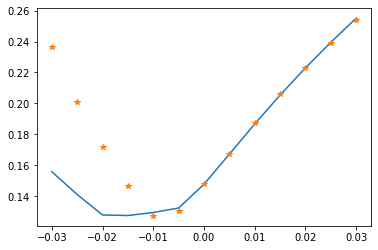

In [64]:
pricesSurface = [capSurface.cap_price(numeroDePagos, F + stkRel, capOrFloor, N) 
                 for (stkRel, capOrFloor) in zip(strikesRelativos, capOrFloors)]
parVolSurface = [par_vol(precio, curvaEst, curvaDesc, numeroDePagos, F + stkRel, capOrFloor, N) 
                 for (precio, stkRel, capOrFloor) in zip(pricesSurface, strikesRelativos, capOrFloors)]
plt.plot(strikesRelativos, parVolSurface)
plt.plot(strikesRelativos, smileCaps, '*')

### Volatilidad FX

In [65]:
def delta_fx(F, K, sigma, T, CoP):
    #F: fwd rate
    #K: strike 
    #T: time to maturity
    #sigma: volatility of underlying asset
    #CoP: 1 for Call, -1 for put 
    # P: Discount factor
    
    # COMPLETAR
        
    d1 = (np.log(F / K) + (.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))

    delta = CoP * si.norm.cdf(CoP * d1, 0.0, 1.0)
    return delta

/home/claudio/anaconda3/envs/tf2/lib/python3.7/site-packages/ipykernel_launcher.py:11: RuntimeWarning: divide by zero encountered in log
  # This is added back by InteractiveShellApp.init_path()


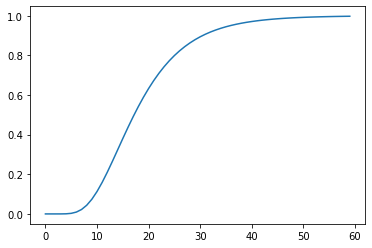

In [69]:
plt.plot([delta_fx(i, 19, .2, 5., 1.) for i in range (60)])

Supon que en mercado cotizan los siguientes quotes

$$\sigma_{ATM} = .2$$
$$\sigma_{RR} = .04$$
$$\sigma_{BF} = 0.03$$

Encuentra las volatilidades $$\sigma_{25C}, \sigma_{25P}$$

In [70]:
def volfx_quotes_a_volatilidades(sigmaATM, sigmaRR, sigmaBF):
    #COMPLETAR
    A = np.array([[1., 0., 0.],
                [0., 1., -1.],
                [-1., .5, .5]])
    b = np.array([sigmaATM, sigmaRR, sigmaBF])
    sigmas = np.linalg.solve(A, b)
    return sigmaATM, sigmas[1], sigmas[2]

In [74]:
sigmaATM = .2
sigmaRR = .04 
sigmaBF = .03
sigmaATM, sigma25C, sigma25P = volfx_quotes_a_volatilidades(sigmaATM, sigmaRR, sigmaBF)
print((sigmaATM, sigma25C, sigma25P))

(0.2, 0.25, 0.21000000000000002)


#### Encontrar strikes de las cotizaciones de mercado

In [81]:
from scipy import optimize
def delta2strikesFX(delta, F, sigma, T, CoP):
    # delta: Numero positivo, por ejemplo si la delta del put es -.25 este input es .25
    
    # COMPLETAR
    fOpt = lambda x: delta_fx(F, x, sigma, T, CoP) - delta
    a = F / 10.
    b = F * 10.
    while fOpt(a) * fOpt(b) > 0:
        a -= .0001 
        b += .0001
    K = optimize.brentq(fOpt, a, b)
    return K

def delta2strikesFX_newton(delta, F, sigma, T, CoP):
    # delta: Numero positivo, por ejemplo si la delta del put es -.25 este input es .25
    # COMPLETAR
    fOpt = lambda x: delta_fx(F, x, sigma, T, CoP) - delta
    K = optimize.newton(fOpt, F)
    return K


In [82]:
CoP = 1.
T = 1.
F = 18.2
delta = .25
K25c = delta2strikesFX_newton(delta, F, sigma25C, T, CoP)
K25p = delta2strikesFX_newton(-delta, F, sigma25P, T, -CoP)
Katm=F
print(Katm,K25p,K25c)

18.2 16.148525521810708 22.226694726012603


### Vega-Vanna-Volga

In [85]:
from scipy.stats import norm
def vegaFX(F, K, sigma, T, P, CoP):
    # COMPLETAR
    h = .0001
    vega = (black(F, K, sigma + h, T, P, CoP) - black(F, K, sigma, T, P, CoP)) / h
    return vega

def vvv_fx(F, K, sigma, T, P, CoP):
    #Vega -vanna-volga
    #F: fwd rate
    #K: strike 
    #T: time to maturity
    #sigma: volatility of underlying asset
    #CoP: 1 for Call, -1 for put 
    # P: Discount factor
    d1 = (np.log(F / K) + (sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - (sigma * np.sqrt(T))
    vega = vegaFX(F, K, sigma, T, P, CoP)
    h = .0001
    volga = (vegaFX(F, K, sigma + h, T, P, CoP) - vega) / h
    vanna =(vegaFX(F + h, K, sigma, T, P, CoP) - vega) / h
    return vega, vanna, volga

In [86]:
def black_vvv_adjusted(F, K,  T, P, CoP, sigmaATM, sigmaRR, sigmaBF):
    #Encontrar strikes
    # COMPLETAR
    sigmaATM, sigma25C, sigma25P =volfx_quotes_a_volatilidades(sigmaATM, sigmaRR, sigmaBF)
    K25C = delta2strikesFX(.25, F, sigma25C, T, 1.)
    K25P = delta2strikesFX(-.25, F, sigma25P, T, -1.)
    Katm = F
    #Encontrar vvv para opciones de mercado con sigmaATM
    #COMPLETAR
    #Encontrar vvv para opcion
    vega, vanna, volga = vvv_fx(F, K, sigmaATM, T, P, CoP)
    print(vega)
    print(vanna)
    print(volga)
    vega25C, vanna25C, volga25C = vvv_fx(F, K25C, sigmaATM, T, P, 1.)
    vega25P, vanna25P, volga25P = vvv_fx(F, K25P, sigmaATM, T, P, -1.)
    vegaATM, vannaATM, volgaATM = vvv_fx(F, Katm, sigmaATM, T, P, 1.)
    # Plantear sistema de ecuaciones
    A = np.array([[vega25C, vega25P, vegaATM],
                 [vanna25C, vanna25P, vannaATM],
                 [volga25C, volga25P, volgaATM]])
    b = np.array([vega, vanna, volga])
    #Resolver sistema
    alpha = np.linalg.solve(A, b)
    # Encontrar precio de opciones de mercado 
    call25Mkt =black(F, K25C, sigma25C, T, P, 1.)
    put25Mkt = black(F, K25P, sigma25P, T, P, -1.)
    callAtmMkt = black(F, Katm, sigmaATM, T, P, 1.)
    call25BS = black(F, K25C, sigmaATM, T, P, 1.)
    put25BS = black(F, K25P, sigmaATM, T, P, -1.)
    callAtmBS = black(F, Katm, sigmaATM, T, P, 1.)
    # Ajustar precio
    precioVolATM = black(F, K, sigmaATM, T, P, CoP)
    precioAjustado = precioVolATM - alpha[0] * (call25BS- call25Mkt) - alpha[1] * (put25BS- put25Mkt) -  alpha[2] * (callAtmBS- callAtmMkt)
    return precioAjustado

In [93]:
K = 15.5
T = 1.
P = .99
F = 18.
CoP = -1.
print ("Opcion no ajustada " + str(black(F, K, sigmaATM, T, P, CoP)))
precioAjustado = black_vvv_adjusted(F, 15,  T, P, CoP, sigmaATM, sigmaRR, sigmaBF)
print ("Opcion ajustada " + str(precioAjustado))

Opcion no ajustada 0.4343047696222637
4.262743190644458
-0.960484647372084
17.47610965385782
Opcion ajustada 0.4394446910113245


In [94]:
sigmaATM, sigma25C, sigma25P = volfx_quotes_a_volatilidades(sigmaATM, sigmaRR, sigmaBF)
K25C = delta2strikesFX(.25, F, sigma25C, T, 1.)
K25P = delta2strikesFX(-.25, F, sigma25P, T, -1.)
Katm = F
print ("Call esperado " + str(black(F, K25C, sigma25C, T, P, 1.)))
precioAjustado = black_vvv_adjusted(F, K25C, T, P, 1., sigmaATM, sigmaRR, sigmaBF)
print ("Call " + str(precioAjustado))

print ("Put esperado " + str(black(F, K25P, sigma25P, T, P, -1.)))
precioAjustado = black_vvv_adjusted(F, K25P, T, P, -1., sigmaATM, sigmaRR, sigmaBF)
print ("Put  " + str(precioAjustado))

Call esperado 0.5896170153320328
4.745533133410085
1.4485247501472287
23.43028855378293
Call 0.5896170153320328
Put esperado 0.6227932871872139
5.572772560296091
-0.7703962801031139
9.670170619813234
Put  0.6227932871872139


In [96]:
print ("Call ATM esperado " + str(black(F, Katm, sigmaATM, T, P, -1.)))
precioAjustado = black_vvv_adjusted(F, Katm, T, P, -1., sigmaATM, sigmaRR, sigmaBF)
print ("Put ATM  " + str(precioAjustado))

Call ATM esperado 1.4194641205533127
7.073676708886367
0.19646353432989372
-0.35385991914438364
Put ATM  1.4194641205533127


### Volatilidad Local

In [66]:
def sabr_a_vol_local(F, K,  T, alpha, beta, rho, volvol):
    delta = 0.0000001
    sigma = sabr_vol(K, F, T, alpha, beta, rho, volvol)
    dSigmadT = (sabr_vol(K, F, T+delta, alpha, beta, rho, volvol)-sigma)/delta
    dSigmadK = (sabr_vol(K+delta, F, T, alpha, beta, rho, volvol)-sigma)/delta
    d2Sigmad2K = (sabr_vol(K+delta, F, T, alpha, beta, rho, volvol)-2*sigma+sabr_vol(K-delta, F, T, alpha, beta, rho, volvol))/delta**2
    numerador = (1. + (2 * T * dSigmadT/sigma))
    d1 = (np.log(F / K) + (sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = (np.log(F / K) - (sigma ** 2) * T) / (sigma * np.sqrt(T))
    denominador1 = 1. + (2. * d1 * (K * dSigmadK * np.sqrt(T)) ) 
    denominador2 = d1 * d2 * (K * dSigmadK *  np.sqrt(T)) ** 2
    denominaor3 = (K * d2Sigmad2K * np.sqrt(T)) * (K * sigma * np.sqrt(T))
    return np.sqrt( (numerador * sigma ** 2) / (denominador1 + denominador2 + denominaor3))

In [67]:
sabr_params
tStart = 28 * 6 / 365.
numeroDePagos = 65
f = tasa_swap_fwd(curvaEst, curvaDesc, tStart, numeroDePagos)
K = f
beta = 1.
alpha = sabr_params[0]
rho  = sabr_params[1]
volvol = sabr_params[2]
sabr_a_vol_local(f, K,  tStart, alpha, beta, rho, volvol)

0.1385510163478627